# Extended Data Fig. 1

Redraws the panels of Extended Data Fig. 1 from the source data.

The source data are deposited on figshare (https://doi.org/10.6084/m9.figshare.34601982): `Wilhelm_SourceData.xlsx` (one worksheet per panel), per-point `Wilhelm_SourceData_*.parquet` files and summary `Wilhelm_SourceData_*.csv` files; `README.md` of the deposit describes all columns. `source_data.py` downloads the files into `./data` on first use. Set `FIGSHARE_ARTICLE_ID` in the next cell (or as environment variable; `FIGSHARE_TOKEN` while the article is private), or point `SOURCE_DATA_DIR` to a local copy of the files.

* a, b, c: worksheets `ED_Fig1a`, `ED_Fig1b`, `ED_Fig1c`
* d, f: `Wilhelm_SourceData_ED_Fig1d_f.parquet` (modified vs unmodified TMT6-labelled spectrum pairs) with `Wilhelm_SourceData_ED_Fig1d.csv` / `Wilhelm_SourceData_ED_Fig1f.csv`
* e: `Wilhelm_SourceData_ED_Fig1e.parquet` (modified vs unmodified unlabelled spectrum pairs) with `Wilhelm_SourceData_ED_Fig1e.csv`


In [1]:
import source_data as sd
from source_data import fetch, readme, table

# figshare article with the source data (https://doi.org/10.6084/m9.figshare.34601982); alternatively set the environment variable
# FIGSHARE_ARTICLE_ID, or SOURCE_DATA_DIR to a local copy of the files. While the article is private, set FIGSHARE_TOKEN.
sd.FIGSHARE_ARTICLE_ID = sd.FIGSHARE_ARTICLE_ID or ""

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

plt.rcParams['pdf.fonttype'] = 42
DATA = Path('data')
DATA.mkdir(exist_ok=True)
FIG_DIR = Path('regenerated_panels') / 'ED_Fig1'
FIG_DIR.mkdir(parents=True, exist_ok=True)


readme('ED_Fig1')

,Figure,Panel,Worksheet,figshare file(s),Content,Tables in worksheet (top to bottom)
0,Extended Data Fig. 1,a,ED_Fig1a,NaN,Peptide sets of the ProteomeTools data used fo...,ED_Fig1a
1,Extended Data Fig. 1,b,ED_Fig1b,NaN,"ProteomeTools data summary (PSMs, modified pep...",ED_Fig1b
2,Extended Data Fig. 1,c,ED_Fig1c,NaN,Recovery rate (%) of TMT6-labelled modified-pe...,ED_Fig1c
3,Extended Data Fig. 1,d,NaN,Wilhelm_SourceData_ED_Fig1d_f.parquet; Wilhelm...,Delta iRT of each modified/unmodified peptide ...,NaN
4,Extended Data Fig. 1,e,NaN,Wilhelm_SourceData_ED_Fig1e.parquet; Wilhelm_S...,Delta iRT of each modified/unmodified peptide ...,NaN
5,Extended Data Fig. 1,f,NaN,Wilhelm_SourceData_ED_Fig1d_f.parquet; Wilhelm...,Spectral angle of each modified/unmodified spe...,NaN


## a — ProteomeTools peptide sets

Peptide sets of the ProteomeTools data used for training (approximate peptide counts); highlighted slices are exploded.

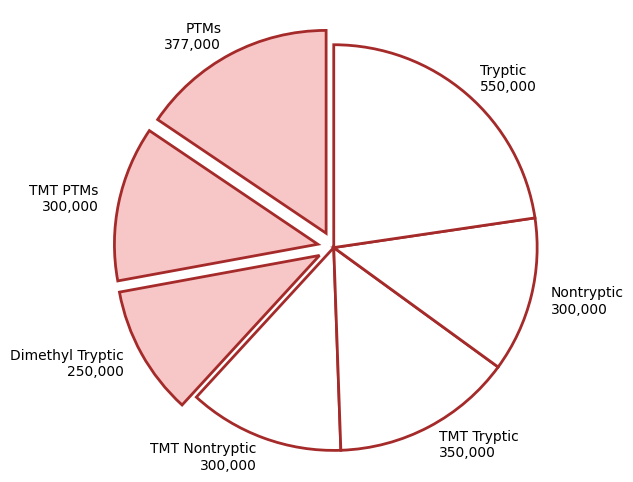

,peptide_set,approximate_count,highlighted_slice
0,PTMs,377000,True
1,TMT PTMs,300000,True
2,Dimethyl Tryptic,250000,True
3,TMT Nontryptic,300000,False
4,TMT Tryptic,350000,False
5,Nontryptic,300000,False
6,Tryptic,550000,False


In [3]:
a = table('ED_Fig1a')
fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(a['approximate_count'], labels=[f"{l}\n{v:,}" for l, v in zip(a.peptide_set, a.approximate_count)],
       explode=np.where(a.highlighted_slice, 0.08, 0), startangle=90,
       colors=np.where(a.highlighted_slice, '#f7c6c7', '#ffffff'),
       wedgeprops=dict(edgecolor='brown', linewidth=2))
ax.axis('equal')
for ext in ('pdf', 'png'):
    plt.savefig(FIG_DIR / f'ED_Fig1a.{ext}', dpi=300, bbox_inches='tight')
plt.show()
a

## b — data set summary

ProteomeTools data summary (PSMs, modified peptides, raw files, pools); numbers only.

In [4]:
table('ED_Fig1b')

,metric,value,unit
0,PSMs,124000000,count
1,Modified peptides,1400000,count
2,Raw files,7877,count
3,Pools,2202,count
4,Packages,56,count
5,Gradient time,331,days


## c — recovery rates of TMT packages

Recovery rate (%) of the TMT6-labelled modified-peptide packages per fragmentation and collision energy (heatmap).

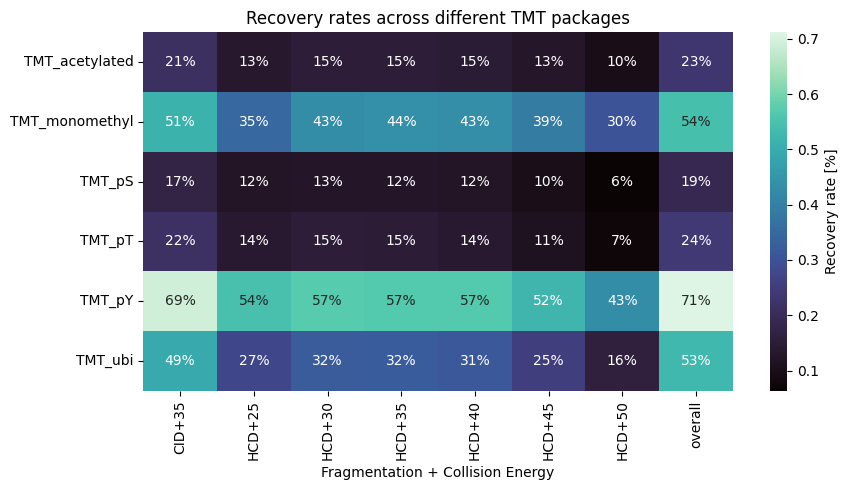

In [5]:
c = table('ED_Fig1c').set_index('package_label').drop(columns='package')
c.columns = [col.replace(' recovery_rate_%', '') for col in c.columns]
fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(c / 100, annot=True, fmt='.0%', cmap=sns.color_palette('mako', as_cmap=True),
            cbar_kws={'label': 'Recovery rate [%]'}, ax=ax)
ax.set_xlabel('Fragmentation + Collision Energy')
ax.set_ylabel('')
ax.set_title('Recovery rates across different TMT packages')
plt.xticks(rotation=90)
plt.tight_layout()
for ext in ('pdf', 'png'):
    plt.savefig(FIG_DIR / f'ED_Fig1c.{ext}', dpi=300, bbox_inches='tight')
plt.show()

## d — ΔiRT between modified and unmodified TMT6-labelled peptides

iRT(modified) - iRT(unmodified) of each pair of spectra with the same peptide sequence, precursor charge and fragmentation (aligned collision energy difference < 0.02), per package. Box plot (seaborn `boxplot`: whiskers 1.5 x IQR, no fliers); pairs without iRT are excluded. Numbers above the boxes: unique modified sequences (`Wilhelm_SourceData_ED_Fig1d.csv`).

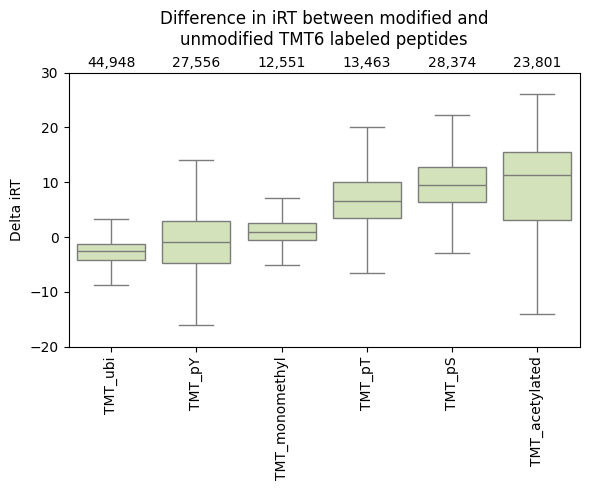

,package_label,package,n_unique_modified_sequences,n_pairs,lower_whisker,Q1,median,Q3,upper_whisker
0,TMT_ubi,TMT_TUM_mod_ubi,44948,34044,-8.822052,-4.260948,-2.604905,-1.219415,3.339755
1,TMT_pY,TMT_TUM_mod_pY,27556,180842,-15.987218,-4.690157,-0.903873,2.844500,14.142636
2,TMT_monomethyl,TMT_TUM_mod_monomethyl,12551,28608,-5.113318,-0.554674,0.855054,2.485432,7.044952
3,TMT_pT,TMT_TUM_mod_pT,13463,19359,-6.557649,3.420261,6.588515,10.091314,20.081550
4,TMT_pS,TMT_TUM_mod_pS,28374,56461,-2.999225,6.452289,9.541511,12.753846,22.204220
5,TMT_acetylated,TMT_TUM_mod_acetylated,23801,383,-14.125263,2.723619,11.166416,14.478741,26.106140


In [6]:
df = pd.read_parquet(fetch('Wilhelm_SourceData_ED_Fig1d_f.parquet'))
d_sum = table('ED_Fig1d')
order_d = d_sum['package_label'].tolist()
fig, ax = plt.subplots(figsize=(6, 5))
sns.boxplot(data=df, x='package_label', y='delta_iRT_modified_minus_unmodified', order=order_d,
            color='#d4e8b5', showfliers=False, ax=ax)
for i, n in enumerate(d_sum['n_unique_modified_sequences']):
    ax.text(i, 31, f'{n:,}', ha='center')
ax.set_ylim(-20, 30)
ax.set_xlabel('')
ax.set_ylabel('Delta iRT')
ax.set_title('Difference in iRT between modified and\nunmodified TMT6 labeled peptides', pad=20)
plt.xticks(rotation=90)
plt.tight_layout()
for ext in ('pdf', 'png'):
    plt.savefig(FIG_DIR / f'ED_Fig1d.{ext}', dpi=300, bbox_inches='tight')
plt.show()
d_sum

## e — ΔiRT between modified and unmodified peptides

As d for the unlabelled packages (aligned collision energy difference < 0.01). Box plot (whiskers 1.5 x IQR, no fliers); numbers above the boxes: unique modified sequences (`Wilhelm_SourceData_ED_Fig1e.csv`).

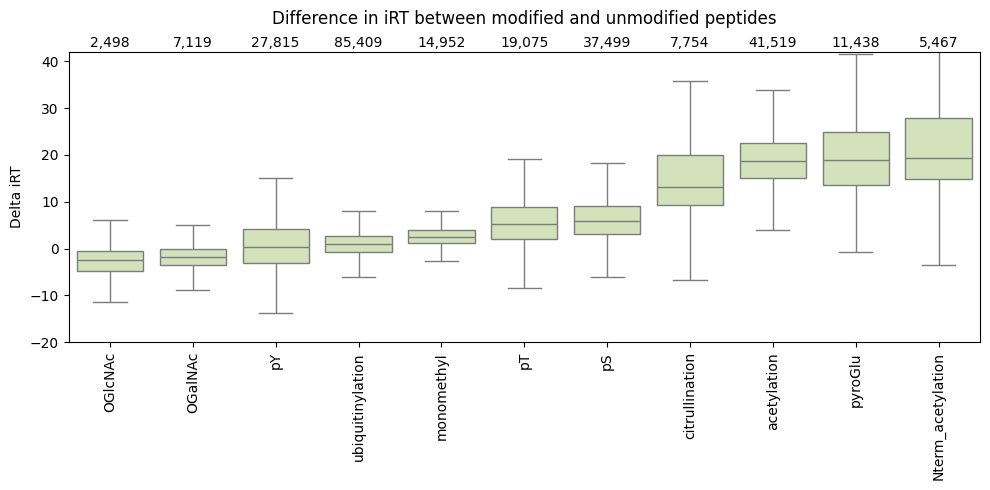

,package_label,package,n_unique_modified_sequences,n_pairs,lower_whisker,Q1,median,Q3,upper_whisker
0,OGlcNAc,TUM_mod_OGlcNAc,2498,4012,-11.438510,-4.840707,-2.344342,-0.438178,6.135239
1,OGalNAc,TUM_mod_OGalNAc,7119,16666,-8.737928,-3.552591,-1.786174,-0.094907,5.086689
2,pY,TUM_mod_pY,27815,159747,-13.846142,-3.026583,0.340363,4.196340,15.029860
3,ubiquitinylation,TUM_mod_ubi,85409,153308,-6.158972,-0.822892,0.870437,2.735421,8.072013
4,monomethyl,TUM_mod_monomethyl,14952,58166,-2.706046,1.280690,2.465035,3.940347,7.924738
5,pT,TUM_mod_pT,19075,45076,-8.339337,1.983413,5.189236,8.865289,19.180969
6,pS,TUM_mod_pS,37499,140986,-5.986040,3.066830,5.887684,9.104143,18.159818
7,citrullination,TUM_mod_citrullination,7754,2088,-6.639903,9.281812,13.068689,19.934882,35.741999
8,acetylation,TUM_mod_acetylated,41519,45761,3.888670,15.105548,18.633555,22.585396,33.781743
9,pyroGlu,TUM_mod_pyroGlu,11438,28974,-0.838943,13.515811,18.943915,24.794971,41.599522


In [7]:
e = pd.read_parquet(fetch('Wilhelm_SourceData_ED_Fig1e.parquet'))
e_sum = table('ED_Fig1e')
order_e = e_sum['package_label'].tolist()
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=e, x='package_label', y='delta_iRT_modified_minus_unmodified', order=order_e,
            color='#d4e8b5', showfliers=False, ax=ax)
for i, n in enumerate(e_sum['n_unique_modified_sequences']):
    ax.text(i, 43, f'{n:,}', ha='center')
ax.set_ylim(-20, 42)
ax.set_xlabel('')
ax.set_ylabel('Delta iRT')
ax.set_title('Difference in iRT between modified and unmodified peptides', pad=20)
plt.xticks(rotation=90)
plt.tight_layout()
for ext in ('pdf', 'png'):
    plt.savefig(FIG_DIR / f'ED_Fig1e.{ext}', dpi=300, bbox_inches='tight')
plt.show()
e_sum

## f — spectral angle between modified and unmodified TMT6-labelled peptides

Spectral angle between the modified and the unmodified spectrum of each pair (pairs as in d), split violins HCD / CID (seaborn `violinplot`, `bw_method=0.3`, default `cut=2`, no inner marks). n = total spectra per package and fragmentation (`Wilhelm_SourceData_ED_Fig1f.csv`).

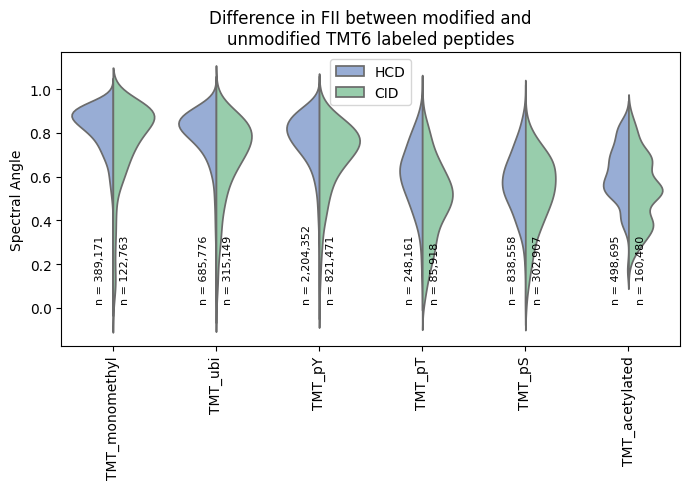

,package_label,package,fragmentation,n_total_spectra,n_pairs,median_spectral_angle
0,TMT_monomethyl,TMT_TUM_mod_monomethyl,HCD,389171,21287,0.850680
1,TMT_monomethyl,TMT_TUM_mod_monomethyl,CID,122763,7883,0.818844
2,TMT_ubi,TMT_TUM_mod_ubi,HCD,685776,22611,0.821050
3,TMT_ubi,TMT_TUM_mod_ubi,CID,315149,13786,0.734578
4,TMT_pY,TMT_TUM_mod_pY,HCD,2204352,128967,0.794959
5,TMT_pY,TMT_TUM_mod_pY,CID,821471,53429,0.728545
6,TMT_pT,TMT_TUM_mod_pT,HCD,248161,11320,0.619561
7,TMT_pT,TMT_TUM_mod_pT,CID,85918,8207,0.504243
8,TMT_pS,TMT_TUM_mod_pS,HCD,838558,36286,0.578116
9,TMT_pS,TMT_TUM_mod_pS,CID,302907,20989,0.544926


In [8]:
f_sum = table('ED_Fig1f')
order_f = f_sum['package_label'].unique().tolist()
fig, ax = plt.subplots(figsize=(7, 5))
sns.violinplot(data=df, x='package_label', y='spectral_angle', hue='fragmentation', hue_order=['HCD', 'CID'],
               split=True, inner=None, bw_method=0.3, order=order_f,
               palette={'HCD': '#8eaadf', 'CID': '#8fd6aa'}, ax=ax)
for i, pkg in enumerate(order_f):
    for frag, dx in [('HCD', -0.12), ('CID', 0.12)]:
        n = f_sum.query('package_label == @pkg and fragmentation == @frag')['n_total_spectra'].iloc[0]
        ax.text(i + dx, 0.02, f'n = {n:,}', rotation=90, ha='center', va='bottom', fontsize=8)
ax.set_xlabel('')
ax.set_ylabel('Spectral Angle')
ax.set_title('Difference in FII between modified and\nunmodified TMT6 labeled peptides')
ax.legend(title='')
plt.xticks(rotation=90)
plt.tight_layout()
for ext in ('pdf', 'png'):
    plt.savefig(FIG_DIR / f'ED_Fig1f.{ext}', dpi=300, bbox_inches='tight')
plt.show()
f_sum